Expected Threat (xT) assigns a value to a pitch location according to the probability of eventually scoring from a possession that starts in that location, under the actions and transitions represented in the model [@singh2018xt]. Unlike expected goals (xG), which evaluates a shot, xT values positions before a shot occurs. A location far from goal can therefore have positive value if possession can progress towards more promising locations.

The xT surface is a location-based estimate that summarizes typical outcomes in the event data, independently of the particular players, defensive pressure or available passing options of an individual tracking frame. PRESS uses the fitted xT grid as a spatial input to its state-dependent action models.

## 1. Mathematical formulation {#mathematical-formulation}

Divide the pitch into cells. For each origin cell $i$, the model needs two distinct quantities: **how often each event occurs**, and **where the ball goes when that event occurs**. The event frequencies are denoted by $p$, the conditional destination distributions by $T$, and the probability of scoring from a shot by $p_{\mathrm{goal}}$.

### Event frequencies: the $p$ terms

For an origin cell $i$, let $n_{\mathrm{pass},i}$ count completed passes released from the cell, $n_{\mathrm{carry},i}$ count within-possession displacements starting there, $n_{\mathrm{shot},i}$ count shots, and $n_{\mathrm{loss},i}$ count terminal losses, which include failed passes. A carry here is a within-possession displacement: it records the movement from the matched beginning to the matched end of individual control, irrespective of the terminal outcome. It covers all possessions and is distinct from the canonical one-second carry. A possession can contribute a displacement followed by a separate pass, shot or loss event.

The four counts share a common denominator,

$$
n_i=n_{\mathrm{pass},i}+n_{\mathrm{carry},i}+n_{\mathrm{shot},i}+n_{\mathrm{loss},i},
\qquad p_{a,i}=\frac{n_{a,i}}{n_i}.
$$

For an observed cell the four frequencies sum to one, and for a cell without events they are zero. They are frequencies in the xT event tables, computed independently of the PRESS action-selection and physical risk models.

Failed actions enter the denominator through the loss count. Hence $p_{\mathrm{pass},i}$ is the probability that a possession in cell $i$ continues with a completed pass, which already accounts for failed attempts, so the value equation below needs no additional pass-success factor. The same holds for $p_{\mathrm{carry},i}$ and $p_{\mathrm{shot},i}$.

### Destinations: the $T$ terms

For passes, let $N^{\mathrm{pass}}_{ij}$ count completed passes from $i$ to $j$. Before the [smoothing](../../../appendix/xt_benchmark.qmd#what-is-smoothed) described below,

$$
T^{\mathrm{pass}}_{ij}
=\frac{N^{\mathrm{pass}}_{ij}}{\sum_kN^{\mathrm{pass}}_{ik}}
=P(\text{destination }j\mid\text{completed pass from }i).
$$

The carry matrix is constructed in the same way from the within-possession displacements. Passes and carries have separate destination counts, and terminal-loss events enter neither matrix. Each row sums to one.

Multiplying $p_{\mathrm{pass},i}$ by $T^{\mathrm{pass}}_{ij}$ combines the frequency of the completed-pass branch with the conditional destination distribution. Before smoothing, this product is simply

$$
p_{\mathrm{pass},i}T^{\mathrm{pass}}_{ij}
=\frac{N^{\mathrm{pass}}_{ij}}{n_i}.
$$

### Value of a cell

Let $p_{\mathrm{goal},i}=P(\mathrm{goal}\mid\mathrm{shot},i)$. The value satisfies

$$
\mathrm{xT}_i = p_{\mathrm{shot},i}p_{\mathrm{goal},i}
+ p_{\mathrm{pass},i}\sum_j T^{\mathrm{pass}}_{ij}\mathrm{xT}_j
+ p_{\mathrm{carry},i}\sum_j T^{\mathrm{carry}}_{ij}\mathrm{xT}_j.
$$

The first term is the immediate scoring contribution. The other terms propagate the value of destination cells through passes and displacements. Terminal loss contributes zero future value. Starting from zero values, this equation is iterated until the surface converges; the iteration converges because losses and shots remove probability mass from the continuing branches at every step.

The original xT formulation [@singh2018xt] groups ball progression into a move branch. The separate pass, carry and zero-value loss branches are the project-specific construction used here.

## 2. Estimation {#estimation}

The production surface is fitted on the event tables of the ten matches, on a 10 × 6 grid. The event frequencies $p_{a,i}$ are computed directly from the counts, while the destination distributions $T$ and the goal probability $p_{\mathrm{goal}}$ are estimated from Gaussian-smoothed counts, with bandwidths of 8 m for passes, 5 m for carries and 5 m for goal given shot. The value equation is then iterated to convergence. The [benchmark](../../../appendix/xt_benchmark.qmd) describes the event cohort, the smoothing, the iteration and the selection of the grid and the bandwidths.

## 3. Fitted xT surface {#fitted-xt-surface}

The heatmap shows the exact production xT values fitted on all ten matches, with the same 10 × 6 cells and no visual interpolation. The saved array has shape `(n_x, n_y)`; its first axis is longitudinal, and its second axis runs from the bottom to the top of the pitch. Both the display and `get_xt_values` use this convention, with attack from left to right.


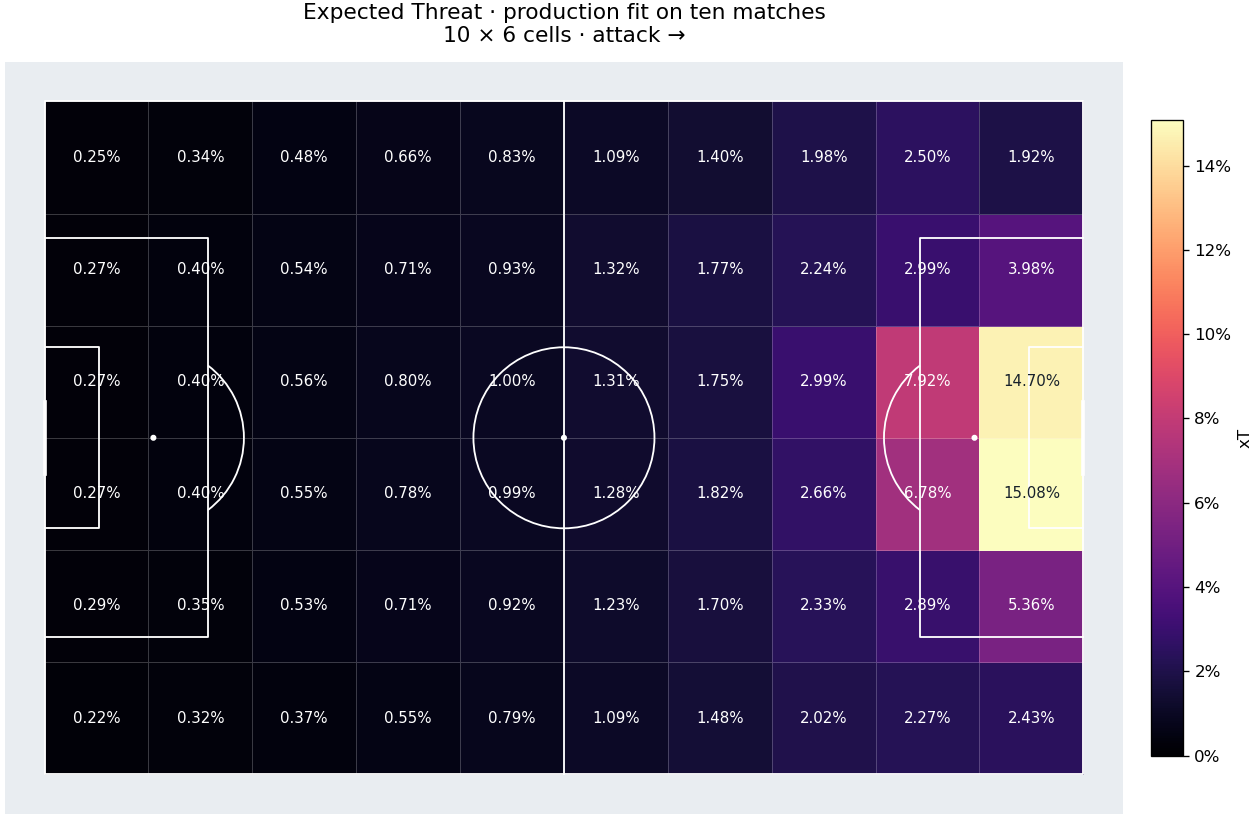

In [3]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "_quarto.yml").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from scripts.build_xt_vignette_figures import plot_xt_surface

# The actual surface distributed with the pretrained choice model.
artifact = json.loads((root / "PRESS/utils/data/pass_selection_model.json").read_text())
xt_grid = np.asarray(artifact["xt_grid"], dtype=float)
fig, ax = plot_xt_surface(xt_grid)
plt.show()


## 4. Using xT in PRESS {#using-xt-in-press}

PRESS expects an xT grid with shape `(n_x, n_y)` and uses centred pitch coordinates. The helper `get_xt_values` evaluates locations for both teams, accounting for attacking direction. The example below reads the locations of the passer and the matched receiver in the real Brisbane FC–Perth Glory pass used in the [action-selection example](../../04_action_selection/04_action_selection.ipynb), together with the fitted grid loaded above.


In [5]:
import os
from PRESS import PRESS
from PRESS.utils.state import get_xt_values

opendata = Path(os.environ.get("SKILLCORNER_OPENDATA", root.parent / "opendata"))
match_dir = opendata / "data/matches/1925299"
press = PRESS.from_skillcorner(match_dir)
release = press.get_frame(54295).iloc[0]
reception = press.get_frame(54309).iloc[0]
passer, receiver = release.player_possession, reception.player_possession
targets = np.asarray([
    [release[f"{passer}_x"], release[f"{passer}_y"]],
    [reception[f"{receiver}_x"], reception[f"{receiver}_y"]],
])
team_xt, opponent_xt = get_xt_values(targets, release.attacking_side, xt_grid)
for name, own, opposite in zip(["N. Acosta at release", "J. Hingert at reception"], team_xt, opponent_xt):
    print(f"{name}: team xT={own:.4f}, opponent xT={opposite:.4f}")


N. Acosta at release: team xT=0.0109, opponent xT=0.0083
J. Hingert at reception: team xT=0.0055, opponent xT=0.0140
